# Does the NIQE vector add on top of T3 on ImageNet-C?

**Question.** Two label-free changes to Ramen's active set each help on ImageNet-C: weighting class queues by the query's zero-shot probabilities (**T3**, +0.62 ± 0.11, seeds 0–4) and adding a whitened NIQE-feature distance to the entry selection (**NIQE**, +0.26 ± 0.04). They act at different levels: T3 picks *which class queues* count, NIQE picks *which entry inside each queue*. Do they add up?

**Hypothesis (pre-registered, `PREREGISTRATION.md`).** Primary: the stack's mean gain over Ramen exceeds the noise floor (2 × Ramen's range over seeds 0–4 = 0.53). Secondary: it beats T3 alone on the mean and on at least 4 of 5 seeds. If the gains added exactly, the stack would give +0.88.

**Why this test.** Both settings were fixed in earlier experiments (λ = 0.1 from `nss_active_set.md`, T = 3 from `active_seeds.py`), so this is a confirmation run with nothing to tune. The single earlier data point, the *scalar*-score regulariser stacked with T3 on seed 0, gave +0.66 vs T3's +0.51.

**Runs** (true labels are used only for scoring and diagnostics):

| Name here | Cached run | What it changes vs Ramen | Run in this experiment? |
|---|---|---|---|
| Ramen | `Ramen` | — (baseline) | no, cached |
| T3 | `active_prob_T3` | class queues weighted by softmax(zero-shot logits / 3) | no, cached (`active_seeds.py`) |
| NIQE | `nss_niqe_white_l0.1` | selection score + 0.1 × whitened NIQE-vector distance | no, cached (`nss_active_set.py`) |
| NIQE + T3 | `nss_niqe_white_l0.1_probT3` | both | **yes** |

**Data.** ImageNet-C 5K (`ImageNetC5K`): 15 corruptions × 5,000 images = 75,000, severity 5, 1,000 classes; each base photo appears under all 15 corruptions. CLIP ViT-B/16, `cfg/ImageNetC5K/RamenNSS.yaml` (capacity 75, top-k 1, β 0, SignSGD lr 0.01), mixed (shuffled) stream, batch 100.

**Seeds.** 0–4. A seed sets the stream order; zero-shot (NoAdapt) is the same for every seed. Every run of a seed sees the identical stream (asserted).

**How the runs were produced.** `python run_stack.py run <seeds>` on 3 GPUs in tmux session `nss_t3_stack` (logs in `logs/`), after `python run_stack.py smoke`. Tables: `python analysis.py` → `tables/`. Harness caches: `../results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s<seed>_<run>.pkl`.

**What counts as a result.** Mean gain over Ramen > 0.53 (primary). Accuracy is domain-averaged (mean of the 15 per-corruption accuracies) throughout.

**Sections.** 1 Setup · 2 Data · 3 Sanity check · 4 Results · 5 Mechanism · 6 Interpretation · 7 Glossary.

## Method: mathematical formulation

**Baseline (Ramen).** Batch $t$ holds $x_1,\dots,x_B$ ($B=100$); $\theta_0$ = the LayerNorm affine parameters of the CLIP image encoder; $w_c$ = normalised text embedding of class $c$.

$$z_i = \frac{f_{\theta_0}(x_i)}{\lVert f_{\theta_0}(x_i)\rVert_2},\quad p_i = \operatorname{softmax}(100\, z_i^\top W),\quad \hat y_i = \arg\max_c p_{ic},\quad H_i = -\textstyle\sum_c p_{ic}\log p_{ic},\quad g_i = \nabla_\theta H_i\big|_{\theta_0}$$

1. **Write** $(z_i, g_i, H_i, \pi_i)$ into the queue $\mathcal{M}_{\hat y_i}$ (capacity $K$, newest kept), before retrieval.
2. **Retrieve** from each non-empty queue $c$ the $k$ entries with the smallest score $s_{ij} = d_{ij} = \lVert z_i - z_j\rVert_2$: $\mathcal{N}_k^c(z_i)$.
3. **Aggregate** $\displaystyle \hat g_i = \frac{1}{|C_i|}\sum_{c\in C_i}\sum_{j\in\mathcal{N}_k^c(z_i)} e^{-H_j} e^{-\beta d_{ij}} g_j$.
4. **Update** $\theta_i = \theta_0 - \eta\,\operatorname{sign}(\hat g_i)$, **predict** with $\theta_i$, reset to $\theta_0$.

**T3 (RamenActive, `active_set: prob`) changes step 3** — each queue is weighted by the query's zero-shot probability at temperature $T$:
$$\hat g_i = \sum_{c\in C_i} q_{ic} \sum_{j\in\mathcal{N}_k^c(z_i)} e^{-H_j} e^{-\beta d_{ij}} g_j,\qquad q_i = \operatorname{softmax}\!\big(100\, z_i^\top W / T\big)$$
(Ramen: $q_{ic} = 1/|C_i|$).

**NIQE (RamenNSS) changes step 2** — the selection score gains a distortion-matching term:
$$s_{ij} = d_{ij} + \lambda\,\frac{\lVert A_t (v_i - \mu_t) - A_t (v_j - \mu_t)\rVert_2}{\sqrt{36}}$$
$v_i \in \mathbb{R}^{36}$ = NIQE's natural-scene-statistics features of image $i$ (AGGD fits to the MSCN coefficients and their paired products, 2 scales), averaged over the image's four 96 px blocks, computed on CLIP's 224 px grey view. $\mu_t, A_t$ = running mean and PCA-whitening map of all $v$ seen up to and including batch $t$ (causal, no labels). Ramen: $\lambda = 0$. The weight in step 3 still uses $d_{ij}$, not $s_{ij}$.

**NIQE + T3** applies both changes; steps 1 and 4 are Ramen's. No term uses the true label $y_i$.

| Symbol | Meaning | Code | Config key | Value |
|---|---|---|---|---|
| $K$ | queue capacity | `PriorityCache.max_capacity` | `max_capacity` | 75 |
| $k$ | entries per queue | `QualityCache.query` | `topk` | 1 |
| $\beta$ | distance temperature | `Ramen.beta` | `beta` | 0 |
| $\eta$ | step size | SignSGD | `lr` | 0.01 |
| $T$ | zero-shot temperature for queue weights | `RamenActive` | `active_set`, `temperature` | prob, 3.0 |
| $\lambda$ | weight of the NIQE term | `RamenNSS.class_penalty` | `nss_lambda` | 0.1 |
| $v$ | NIQE feature vector | `ImageQuality.with_features` (`src/models/iqa.py`) | `nss_features` | niqe |
| $A_t, \mu_t$ | causal whitening | `StreamNormaliser` | `nss_norm` | white |

## 1. Setup

In [1]:
import pandas as pd
import analysis as A
import plots
pd.set_option('display.width', 200)
per_seed = pd.read_csv('tables/per_seed.csv')
summary = pd.read_csv('tables/summary.csv')
corr = pd.read_csv('tables/per_corruption.csv')
FLOOR, RAMEN_ACCS = A.noise_floor()
print(f'seeds analysed: {sorted(per_seed.seed.unique())}; noise floor {FLOOR:.2f}')

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


seeds analysed: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]; noise floor 0.53


## 2. The data the code ran on

In [2]:
s0 = A.SeedRuns(0)
z = s0.df['Ramen']
n = len(z)
print(f'{n:,} images, {z.label.nunique():,} classes present, {len(s0.corruptions)} corruptions x {n // len(s0.corruptions):,}')
pd.DataFrame({'images': z.groupby('domain', observed=True).size(),
              'Ramen correct (seed 0)': z.groupby('domain', observed=True).correct.sum(),
              'Ramen acc % (seed 0)': (z.groupby('domain', observed=True).correct.mean() * 100).round(2)})

75,000 images, 997 classes present, 15 corruptions x 5,000


,images,Ramen correct (seed 0),Ramen acc % (seed 0)
domain,,,
gaussian_noise,5000,1112,22.24
shot_noise,5000,1159,23.18
impulse_noise,5000,1182,23.64
defocus_blur,5000,1426,28.52
glass_blur,5000,1210,24.20
motion_blur,5000,1644,32.88
zoom_blur,5000,1488,29.76
snow,5000,1870,37.40
frost,5000,1749,34.98


In [3]:
pd.Series({**{f'Ramen seed {s}': round(a, 2) for s, a in enumerate(RAMEN_ACCS)},
           'range': round(max(RAMEN_ACCS) - min(RAMEN_ACCS), 2), 'noise floor (2 x range)': round(FLOOR, 2)})

Ramen seed 0               33.08
Ramen seed 1               33.17
Ramen seed 2               33.02
Ramen seed 3               32.91
Ramen seed 4               32.96
range                       0.27
noise floor (2 x range)     0.53
dtype: float64

## 3. Sanity check

`run_stack.py smoke` on a 3,000-image subset (15 × 200, seed 0): RamenNSS with λ = 0 and T3 settings made the same prediction as RamenActive prob T3 on **3,000 of 3,000 images (100.00%)**, so the stack differs from T3 only through the NIQE term. At λ = 0.1 the stack changed 377 of 3,000 predictions. Every run of a seed is asserted to see the same stream order (`analysis.SeedRuns`).

In [4]:
print(open('logs/smoke.log').read().split('mixed')[-1].strip())

smoke_active_prob_T3: 100%|██████████| 30/30 [00:18<00:00,  1.59it/s]

smoke_nss_l0_probT3: 100%|██████████| 30/30 [00:24<00:00,  1.24it/s]

smoke_nss_niqe_white_l0.1_probT3: 100%|██████████| 30/30 [00:27<00:00,  1.09it/s]
lambda 0 vs RamenActive prob T3: 100.00% same predictions (3,000 of 3,000)
stack lambda 0.1 differs on 377 of 3,000
SMOKE OK


## 4. Results

### Gain over Ramen, seeds 0–4

In [5]:
t = per_seed.copy()
t['correct'] = (t.acc / 100 * 75000).round().astype(int)
t['images vs Ramen'] = (t['gain vs Ramen'] / 100 * 75000).round()
t[['seed', 'run', 'acc', 'gain vs Ramen', 'CI low vs Ramen', 'CI high vs Ramen', 'images vs Ramen',
   'gain vs T3', 'fixed vs T3', 'broken vs T3']].round(2)

,seed,run,acc,gain vs Ramen,CI low vs Ramen,CI high vs Ramen,images vs Ramen,gain vs T3,fixed vs T3,broken vs T3
0,0,Ramen,33.08,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0,T3,33.59,0.51,0.29,0.71,380.0,NaN,NaN,NaN
2,0,NIQE,33.35,0.27,0.14,0.40,202.0,NaN,NaN,NaN
3,0,NIQE + T3,33.84,0.76,0.56,0.98,572.0,0.26,1338.0,1146.0
4,1,Ramen,33.17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,1,T3,33.69,0.51,0.32,0.71,386.0,NaN,NaN,NaN
6,1,NIQE,33.45,0.27,0.13,0.41,205.0,NaN,NaN,NaN
7,1,NIQE + T3,33.97,0.80,0.60,1.00,601.0,0.29,1315.0,1100.0
8,2,Ramen,33.02,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2,T3,33.75,0.73,0.53,0.94,548.0,NaN,NaN,NaN


In [6]:
summary.round(2)

,run,seeds,gain vs Ramen mean,std,min,positive seeds,paired t,above floor,same-corruption top8 %,gain vs T3 mean,gain vs T3 std,seeds above T3
0,T3,5,0.62,0.11,0.51,5,12.90,True,58.96,NaN,NaN,NaN
1,NIQE,5,0.26,0.04,0.20,5,14.26,False,49.43,NaN,NaN,NaN
2,NIQE + T3,5,0.87,0.10,0.76,5,20.07,True,62.50,0.25,0.05,5.0


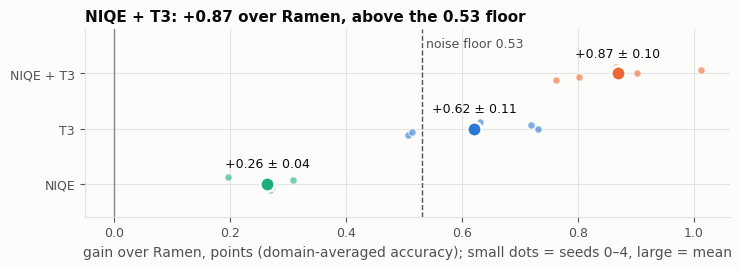

In [7]:
fig = plots.seed_gains(per_seed, FLOOR)

### Does NIQE add on top of T3? (paired, same stream)

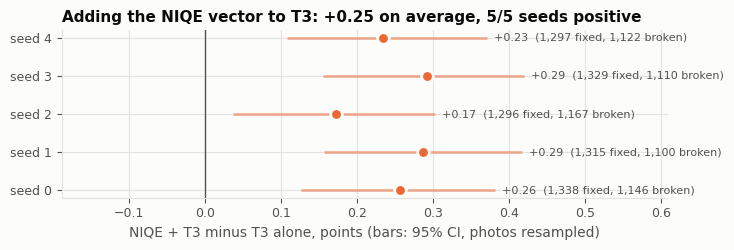

In [8]:
fig = plots.stack_vs_t3(per_seed)

### Per corruption

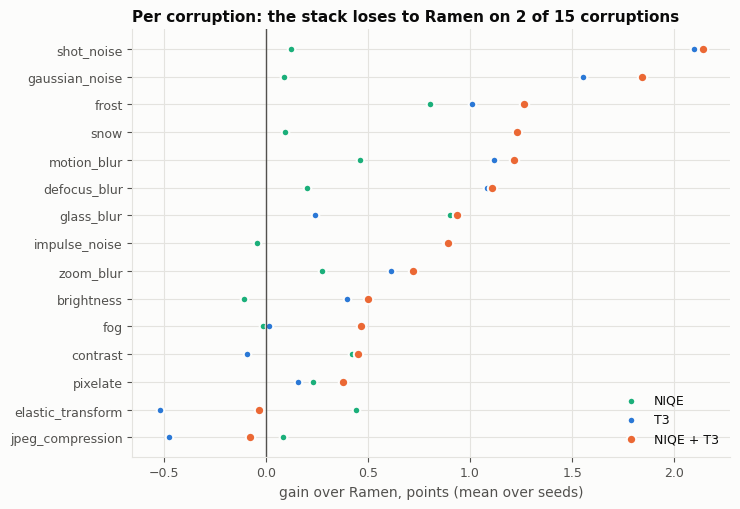

In [9]:
fig = plots.per_corruption(corr)

In [10]:
corr[corr.run != 'Ramen'].groupby(['corruption', 'run'])['gain vs Ramen'].mean().unstack()[plots.ORDER].round(2)

run,NIQE,T3,NIQE + T3
corruption,,,
brightness,-0.11,0.40,0.50
contrast,0.42,-0.09,0.45
defocus_blur,0.20,1.08,1.11
elastic_transform,0.44,-0.52,-0.03
fog,-0.01,0.02,0.47
frost,0.80,1.01,1.26
gaussian_noise,0.09,1.55,1.84
glass_blur,0.90,0.24,0.94
impulse_noise,-0.04,0.88,0.89


## 5. Mechanism: does the stack retrieve more same-corruption support?

Both components were earlier found to work by changing *where* the update comes from; NIQE in particular raised the same-corruption share of the retrieved entries. Logged: the stream ids and weights of each query's 8 highest-weighted retrieved entries.

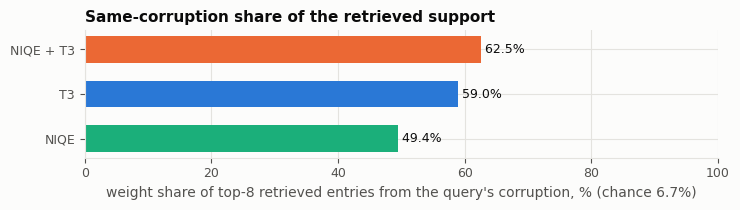

In [11]:
fig = plots.same_corruption(summary)

## 6. Interpretation

**What the numbers say**

- **Both pre-registered claims pass.** NIQE + T3 gains **+0.87 ± 0.10** over Ramen (seeds 0–4, all 5 positive, paired t 20.1). The mean clears the 0.53 noise floor, and so does every single seed (smallest +0.76). Each seed's photo-clustered 95% CI excludes 0 (lowest lower bound +0.56). This is the first ImageNet-C variant whose every seed is above the floor; T3 alone (+0.62) cleared it only on the mean.
- **The stack beats T3 alone on 5 of 5 seeds**, by **+0.25 ± 0.05**. Every seed's CI vs T3 excludes 0 (+0.04 to +0.42 at the extremes). In images: about 1,300 fixed vs about 1,130 broken relative to T3 per seed. The net gain of ~190 images out of 75,000 is small compared with the churn.
- **The gains add almost exactly.** T3 alone +0.62 plus NIQE alone +0.26 predicts +0.88; the stack gives +0.87. This fits the design: T3 reweights *which class queues* count, NIQE changes *which entry within a queue* is picked, and the two do not appear to interfere.

**Where the extra gain comes from (per corruption, mean over seeds)**

- NIQE fills in where T3 hurts. T3 loses to Ramen on elastic (−0.52), jpeg (−0.48) and contrast (−0.09), and gains little on fog (+0.02) and glass blur (+0.24). The stack gives −0.03, −0.08, +0.45, +0.47 and +0.94 on these. These are the structured, non-additive distortions where NIQE alone helps most (glass blur +0.90, elastic +0.44, contrast +0.42).
- On the noise corruptions, where T3's gain is already large, the stack adds little (shot +2.10 → +2.14, impulse +0.88 → +0.89).
- The stack now loses to Ramen on only 2 of 15 corruptions, both within 0.1 points (elastic −0.03, jpeg −0.08).

**Mechanism: partly measured**

- Measured: the weight share of the top-8 retrieved entries that share the query's corruption rises from 59.0% (T3) to 62.5% (stack). NIQE alone gives 49.4%; Ramen was 43.6% in `nss_active_set.md`.
- Not established: that this share *causes* the gain. NIQE adds only +3.5 points of same-corruption share on top of T3 (vs +5.8 on top of Ramen), yet its full accuracy gain carries over. Something beyond the corruption share may matter, for example *which* same-corruption entry gets picked. Treat the share as a correlate, not the mechanism.

**Caveats**

- **Not held-out.** Both settings were picked on ImageNet-C: λ = 0.1 from the seed-0 replay and real runs, T = 3 from the seed-0 sweep. This run confirms the stack across seeds on the dataset that set its settings, so it is not yet a generalisation claim.
- **Cost.** About 17–20 min per run vs ~7 for Ramen, mostly from RamenQuality's per-class rank work, which is unused when `quality_lambda = 0`, plus NIQE feature extraction.

**Next step**

Pre-registered held-out test with both settings frozen. ImageNet-R/A/Sketch is the natural first target: T3 already holds there (+0.59 ± 0.04), and the loader and cached Ramen/T3 runs exist. Unknown: whether NIQE features mean anything on renditions and sketches; flat sketch backgrounds hit the same MSCN degeneracy as quickdraw. DomainNet needs the offline replay extended to β = 5 first. A failure on R/A/Sketch would say the NIQE part only helps when the domain shift is a pixel-level corruption.


## Glossary

| Term | Meaning |
|---|---|
| Ramen | The baseline test-time adaptation method: per-class memory of entropy gradients, one SignSGD step per image from retrieved entries, then reset. |
| Active set | The memory entries a query retrieves and combines into its update. |
| T3 | RamenActive with `active_set: prob`, temperature 3: class queues weighted by the query's zero-shot probabilities instead of equally. |
| NIQE vector | The 36 natural-scene-statistics features behind the NIQE quality score; here a descriptor of *which distortion* an image has, not of its quality. |
| Whitening | Linear map that decorrelates the features and scales them to unit variance, fitted on the stream seen so far. |
| Same-corruption share | Weight share of the 8 highest-weighted retrieved entries whose corruption equals the query's (chance 1/15 = 6.7%). |
| Noise floor | 2 × (max − min) of Ramen's accuracy over seeds 0–4. A mean gain must exceed it to count as established. |
| Fixed / broken vs T3 | Images T3 gets wrong and the stack gets right / T3 right and the stack wrong. |
| Domain-averaged accuracy | Mean of the 15 per-corruption accuracies (all corruptions have 5,000 images here, so it equals pooled accuracy). |
| Photo-clustered CI | Bootstrap that resamples base photos (each appears under 15 corruptions), so correlated copies are not counted as independent. |